In [59]:

'''Objective 1

1. Import & QA the data
2. Your first objective is to import & join two customer data tables, then remove duplicate rows & columns and fill in missing values'''


'Objective 1\n\n1. Import & QA the data\n2. Your first objective is to import & join two customer data tables, then remove duplicate rows & columns and fill in missing values'

In [60]:
# Import & QA the data

import pandas as pd
import numpy as np

customer_info = pd.read_excel(r"C:\Users\Ahasan Hasan\Desktop\Portfolio\Bnak_customer_churn_analysis\Bank_Churn_Messy.xlsx")
customer_info.head()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,EstimatedSalary
0,15634602,Hargrave,619,FRA,Female,42.0,2,€101348.88
1,15647311,Hill,608,Spain,Female,41.0,1,€112542.58
2,15619304,Onio,502,French,Female,42.0,8,€113931.57
3,15701354,Boni,699,FRA,Female,39.0,1,€93826.63
4,15737888,Mitchell,850,Spain,Female,43.0,2,€79084.1


In [61]:
customer_info.head()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,EstimatedSalary
0,15634602,Hargrave,619,FRA,Female,42.0,2,€101348.88
1,15647311,Hill,608,Spain,Female,41.0,1,€112542.58
2,15619304,Onio,502,French,Female,42.0,8,€113931.57
3,15701354,Boni,699,FRA,Female,39.0,1,€93826.63
4,15737888,Mitchell,850,Spain,Female,43.0,2,€79084.1


In [62]:
account_info = pd.read_excel(r"C:\Users\Ahasan Hasan\Desktop\Portfolio\Bnak_customer_churn_analysis\Bank_Churn_Messy.xlsx",sheet_name=1)
customer_info.head()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,EstimatedSalary
0,15634602,Hargrave,619,FRA,Female,42.0,2,€101348.88
1,15647311,Hill,608,Spain,Female,41.0,1,€112542.58
2,15619304,Onio,502,French,Female,42.0,8,€113931.57
3,15701354,Boni,699,FRA,Female,39.0,1,€93826.63
4,15737888,Mitchell,850,Spain,Female,43.0,2,€79084.1


In [63]:
# Customer_info is a left table here,

churn_cus_info = customer_info.merge(account_info, how='left', on = 'CustomerId')
churn_cus_info.head()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure_x,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure_y,IsActiveMember,Exited
0,15634602,Hargrave,619,FRA,Female,42.0,2,€101348.88,€0.0,1,Yes,2,Yes,1
1,15634602,Hargrave,619,FRA,Female,42.0,2,€101348.88,€0.0,1,Yes,2,Yes,1
2,15647311,Hill,608,Spain,Female,41.0,1,€112542.58,€83807.86,1,Yes,1,Yes,0
3,15619304,Onio,502,French,Female,42.0,8,€113931.57,€159660.8,3,No,8,No,1
4,15701354,Boni,699,FRA,Female,39.0,1,€93826.63,€0.0,2,No,1,No,0


In [64]:
churn_cus_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 10004 entries, 0 to 10003
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10004 non-null  int64  
 1   Surname          10001 non-null  str    
 2   CreditScore      10004 non-null  int64  
 3   Geography        10004 non-null  str    
 4   Gender           10004 non-null  str    
 5   Age              10001 non-null  float64
 6   Tenure_x         10004 non-null  int64  
 7   EstimatedSalary  10004 non-null  str    
 8   Balance          10004 non-null  str    
 9   NumOfProducts    10004 non-null  int64  
 10  HasCrCard        10004 non-null  str    
 11  Tenure_y         10004 non-null  int64  
 12  IsActiveMember   10004 non-null  str    
 13  Exited           10004 non-null  int64  
dtypes: float64(1), int64(6), str(7)
memory usage: 1.1 MB


In [65]:
# Drop duplicate column (Tenure)
churn_cus_info = churn_cus_info.drop("Tenure_x", axis = 1).rename({"Tenure_y": "Tenure"}, axis = 1)

churn_cus_info.head()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure,IsActiveMember,Exited
0,15634602,Hargrave,619,FRA,Female,42.0,€101348.88,€0.0,1,Yes,2,Yes,1
1,15634602,Hargrave,619,FRA,Female,42.0,€101348.88,€0.0,1,Yes,2,Yes,1
2,15647311,Hill,608,Spain,Female,41.0,€112542.58,€83807.86,1,Yes,1,Yes,0
3,15619304,Onio,502,French,Female,42.0,€113931.57,€159660.8,3,No,8,No,1
4,15701354,Boni,699,FRA,Female,39.0,€93826.63,€0.0,2,No,1,No,0


In [66]:
churn_cus_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 10004 entries, 0 to 10003
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10004 non-null  int64  
 1   Surname          10001 non-null  str    
 2   CreditScore      10004 non-null  int64  
 3   Geography        10004 non-null  str    
 4   Gender           10004 non-null  str    
 5   Age              10001 non-null  float64
 6   EstimatedSalary  10004 non-null  str    
 7   Balance          10004 non-null  str    
 8   NumOfProducts    10004 non-null  int64  
 9   HasCrCard        10004 non-null  str    
 10  Tenure           10004 non-null  int64  
 11  IsActiveMember   10004 non-null  str    
 12  Exited           10004 non-null  int64  
dtypes: float64(1), int64(5), str(7)
memory usage: 1016.2 KB


In [67]:
# lets check duplicate row
churn_cus_info.duplicated(keep=False)

0         True
1         True
2        False
3        False
4        False
         ...  
9999     False
10000     True
10001     True
10002     True
10003     True
Length: 10004, dtype: bool

In [68]:
# verify duplicates row
churn_cus_info.head()
churn_cus_info.tail()  # shows last 4 rows are same data

,CustomerId,Surname,CreditScore,Geography,Gender,Age,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure,IsActiveMember,Exited
9999,15682355,Sabbatini,772,Germany,Male,42.0,€92888.52,€75075.31,2,No,3,No,1
10000,15628319,Walker,792,French,Female,28.0,€38190.78,€130142.79,1,No,4,No,0
10001,15628319,Walker,792,French,Female,28.0,€38190.78,€130142.79,1,No,4,No,0
10002,15628319,Walker,792,French,Female,28.0,€38190.78,€130142.79,1,No,4,No,0
10003,15628319,Walker,792,French,Female,28.0,€38190.78,€130142.79,1,No,4,No,0


In [69]:
# Let's delete all duplicate row

churn_cus_info = churn_cus_info.drop_duplicates()
churn_cus_info

,CustomerId,Surname,CreditScore,Geography,Gender,Age,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure,IsActiveMember,Exited
0,15634602,Hargrave,619,FRA,Female,42.0,€101348.88,€0.0,1,Yes,2,Yes,1
2,15647311,Hill,608,Spain,Female,41.0,€112542.58,€83807.86,1,Yes,1,Yes,0
3,15619304,Onio,502,French,Female,42.0,€113931.57,€159660.8,3,No,8,No,1
4,15701354,Boni,699,FRA,Female,39.0,€93826.63,€0.0,2,No,1,No,0
5,15737888,Mitchell,850,Spain,Female,43.0,€79084.1,€125510.82,1,Yes,2,Yes,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9996,15606229,Obijiaku,771,France,Male,39.0,€96270.64,€0.0,2,No,5,No,0
9997,15569892,Johnstone,516,French,Male,35.0,€101699.77,€57369.61,1,Yes,10,Yes,0
9998,15584532,Liu,709,FRA,Female,36.0,€42085.58,€0.0,1,Yes,7,Yes,1
9999,15682355,Sabbatini,772,Germany,Male,42.0,€92888.52,€75075.31,2,No,3,No,1


In [70]:
# Verify is there any duplicate value or not
churn_cus_info.info()

<class 'pandas.DataFrame'>
Index: 10000 entries, 0 to 10000
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10000 non-null  int64  
 1   Surname          9997 non-null   str    
 2   CreditScore      10000 non-null  int64  
 3   Geography        10000 non-null  str    
 4   Gender           10000 non-null  str    
 5   Age              9997 non-null   float64
 6   EstimatedSalary  10000 non-null  str    
 7   Balance          10000 non-null  str    
 8   NumOfProducts    10000 non-null  int64  
 9   HasCrCard        10000 non-null  str    
 10  Tenure           10000 non-null  int64  
 11  IsActiveMember   10000 non-null  str    
 12  Exited           10000 non-null  int64  
dtypes: float64(1), int64(5), str(7)
memory usage: 1.1 MB


In [71]:
'''
Objective 2
Clean the data
Your second objective is to clean the data by fixing inconsistencies in labeling, handling erroneous values, and fixing currency fields.

Task
1. Check the data types for each column and make any necessary fixes

2. Replace missing values in categorical columns with "MISSING", and missing values in numeric columns with the median

3. Profile the numeric columns in the data. Are there any extreme or non-sensical values? If so, impute them with the median of the column.

4. Combine any variations in country names in the "Geography" column to a single value per country'''

'\nObjective 2\nClean the data\nYour second objective is to clean the data by fixing inconsistencies in labeling, handling erroneous values, and fixing currency fields.\n\nTask\n1. Check the data types for each column and make any necessary fixes\n\n2. Replace missing values in categorical columns with "MISSING", and missing values in numeric columns with the median\n\n3. Profile the numeric columns in the data. Are there any extreme or non-sensical values? If so, impute them with the median of the column.\n\n4. Combine any variations in country names in the "Geography" column to a single value per country'

In [72]:
# change data types and remove unnecessary symbol (€)
churn_cus_info["EstimatedSalary"] = churn_cus_info["EstimatedSalary"].str.replace("€","").astype(float)
churn_cus_info

,CustomerId,Surname,CreditScore,Geography,Gender,Age,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure,IsActiveMember,Exited
0,15634602,Hargrave,619,FRA,Female,42.0,101348.88,€0.0,1,Yes,2,Yes,1
2,15647311,Hill,608,Spain,Female,41.0,112542.58,€83807.86,1,Yes,1,Yes,0
3,15619304,Onio,502,French,Female,42.0,113931.57,€159660.8,3,No,8,No,1
4,15701354,Boni,699,FRA,Female,39.0,93826.63,€0.0,2,No,1,No,0
5,15737888,Mitchell,850,Spain,Female,43.0,79084.10,€125510.82,1,Yes,2,Yes,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9996,15606229,Obijiaku,771,France,Male,39.0,96270.64,€0.0,2,No,5,No,0
9997,15569892,Johnstone,516,French,Male,35.0,101699.77,€57369.61,1,Yes,10,Yes,0
9998,15584532,Liu,709,FRA,Female,36.0,42085.58,€0.0,1,Yes,7,Yes,1
9999,15682355,Sabbatini,772,Germany,Male,42.0,92888.52,€75075.31,2,No,3,No,1


In [73]:
# change data types and remove unnecessary symbol (€) for balance column
churn_cus_info["Balance"] = churn_cus_info["Balance"].str.replace("€","").astype(float)
churn_cus_info

,CustomerId,Surname,CreditScore,Geography,Gender,Age,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure,IsActiveMember,Exited
0,15634602,Hargrave,619,FRA,Female,42.0,101348.88,0.00,1,Yes,2,Yes,1
2,15647311,Hill,608,Spain,Female,41.0,112542.58,83807.86,1,Yes,1,Yes,0
3,15619304,Onio,502,French,Female,42.0,113931.57,159660.80,3,No,8,No,1
4,15701354,Boni,699,FRA,Female,39.0,93826.63,0.00,2,No,1,No,0
5,15737888,Mitchell,850,Spain,Female,43.0,79084.10,125510.82,1,Yes,2,Yes,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9996,15606229,Obijiaku,771,France,Male,39.0,96270.64,0.00,2,No,5,No,0
9997,15569892,Johnstone,516,French,Male,35.0,101699.77,57369.61,1,Yes,10,Yes,0
9998,15584532,Liu,709,FRA,Female,36.0,42085.58,0.00,1,Yes,7,Yes,1
9999,15682355,Sabbatini,772,Germany,Male,42.0,92888.52,75075.31,2,No,3,No,1


In [74]:
# let's check which row has missing values

churn_cus_info[churn_cus_info.isna().any(axis=1) == True]   #there are 2 column has missing value Surname and Age



,CustomerId,Surname,CreditScore,Geography,Gender,Age,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure,IsActiveMember,Exited
29,15728693,NaN,574,Germany,Female,NaN,-999999.0,141349.43,1,Yes,3,Yes,0
122,15580203,NaN,674,Spain,Male,NaN,-999999.0,120193.42,1,No,6,No,0
9390,15756954,NaN,538,France,Female,NaN,-999999.0,0.00,1,Yes,2,Yes,0


In [75]:
# Fill missing values in surname and use Median value in age

churn_cus_info = churn_cus_info.fillna({"Surname": "Missing","Age": churn_cus_info["Age"].median()})
churn_cus_info

,CustomerId,Surname,CreditScore,Geography,Gender,Age,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure,IsActiveMember,Exited
0,15634602,Hargrave,619,FRA,Female,42.0,101348.88,0.00,1,Yes,2,Yes,1
2,15647311,Hill,608,Spain,Female,41.0,112542.58,83807.86,1,Yes,1,Yes,0
3,15619304,Onio,502,French,Female,42.0,113931.57,159660.80,3,No,8,No,1
4,15701354,Boni,699,FRA,Female,39.0,93826.63,0.00,2,No,1,No,0
5,15737888,Mitchell,850,Spain,Female,43.0,79084.10,125510.82,1,Yes,2,Yes,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9996,15606229,Obijiaku,771,France,Male,39.0,96270.64,0.00,2,No,5,No,0
9997,15569892,Johnstone,516,French,Male,35.0,101699.77,57369.61,1,Yes,10,Yes,0
9998,15584532,Liu,709,FRA,Female,36.0,42085.58,0.00,1,Yes,7,Yes,1
9999,15682355,Sabbatini,772,Germany,Male,42.0,92888.52,75075.31,2,No,3,No,1


In [76]:
# let's verify
churn_cus_info.iloc[[28,121,9389]]

,CustomerId,Surname,CreditScore,Geography,Gender,Age,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure,IsActiveMember,Exited
29,15728693,Missing,574,Germany,Female,37.0,-999999.0,141349.43,1,Yes,3,Yes,0
122,15580203,Missing,674,Spain,Male,37.0,-999999.0,120193.42,1,No,6,No,0
9390,15756954,Missing,538,France,Female,37.0,-999999.0,0.00,1,Yes,2,Yes,0


In [77]:
# Let's verify overview of the table
churn_cus_info.describe()

,CustomerId,CreditScore,Age,EstimatedSalary,Balance,NumOfProducts,Tenure,Exited
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,1.569094e+07,650.528800,38.921500,99762.195289,76485.889288,1.530200,5.012800,0.203700
std,7.193619e+04,96.653299,10.487552,60583.863580,62397.405202,0.581654,2.892174,0.402769
min,1.556570e+07,350.000000,18.000000,-999999.000000,0.000000,1.000000,0.000000,0.000000
25%,1.562853e+07,584.000000,32.000000,50910.677500,0.000000,1.000000,3.000000,0.000000
50%,1.569074e+07,652.000000,37.000000,100191.725000,97198.540000,1.000000,5.000000,0.000000
75%,1.575323e+07,718.000000,44.000000,149388.247500,127644.240000,2.000000,7.000000,0.000000
max,1.581569e+07,850.000000,92.000000,199992.480000,250898.090000,4.000000,10.000000,1.000000


In [78]:
churn_cus_info["EstimatedSalary"] = churn_cus_info["EstimatedSalary"].replace(-999999,churn_cus_info["EstimatedSalary"].median())

churn_cus_info



,CustomerId,Surname,CreditScore,Geography,Gender,Age,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure,IsActiveMember,Exited
0,15634602,Hargrave,619,FRA,Female,42.0,101348.88,0.00,1,Yes,2,Yes,1
2,15647311,Hill,608,Spain,Female,41.0,112542.58,83807.86,1,Yes,1,Yes,0
3,15619304,Onio,502,French,Female,42.0,113931.57,159660.80,3,No,8,No,1
4,15701354,Boni,699,FRA,Female,39.0,93826.63,0.00,2,No,1,No,0
5,15737888,Mitchell,850,Spain,Female,43.0,79084.10,125510.82,1,Yes,2,Yes,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9996,15606229,Obijiaku,771,France,Male,39.0,96270.64,0.00,2,No,5,No,0
9997,15569892,Johnstone,516,French,Male,35.0,101699.77,57369.61,1,Yes,10,Yes,0
9998,15584532,Liu,709,FRA,Female,36.0,42085.58,0.00,1,Yes,7,Yes,1
9999,15682355,Sabbatini,772,Germany,Male,42.0,92888.52,75075.31,2,No,3,No,1


In [79]:
churn_cus_info["Geography"].value_counts()

Geography
Germany    2509
Spain      2477
France     1741
French     1655
FRA        1618
Name: count, dtype: int64

In [80]:
# Text manipulation "Geography"

churn_cus_info["Geography"] = np.where(churn_cus_info["Geography"].isin(["FRA","France","French"]),"France",churn_cus_info["Geography"])
churn_cus_info["Geography"].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [81]:
'''Objective 3
Explore the data
Third objective is to explore the target variable and look at feature-target relationships for categorical and numeric fields.

1. Build a bar chart displaying the count of churners (Exited=1) vs. non-churners (Exited=0)

2. Explore the categorical variables vs. the target, and look at the percentage of Churners by “Geography” and “Gender”

3. Build box plots for each numeric field, broken out by churners vs. non-churners

4. Build histograms for each numeric field, broken out by churners vs. non-churners'''

'Objective 3\nExplore the data\nThird objective is to explore the target variable and look at feature-target relationships for categorical and numeric fields.\n\n1. Build a bar chart displaying the count of churners (Exited=1) vs. non-churners (Exited=0)\n\n2. Explore the categorical variables vs. the target, and look at the percentage of Churners by “Geography” and “Gender”\n\n3. Build box plots for each numeric field, broken out by churners vs. non-churners\n\n4. Build histograms for each numeric field, broken out by churners vs. non-churners'

In [82]:
print(churn_cus_info.head())
churn_cus_info.info()


   CustomerId   Surname  CreditScore Geography  Gender   Age  EstimatedSalary  \
0    15634602  Hargrave          619    France  Female  42.0        101348.88   
2    15647311      Hill          608     Spain  Female  41.0        112542.58   
3    15619304      Onio          502    France  Female  42.0        113931.57   
4    15701354      Boni          699    France  Female  39.0         93826.63   
5    15737888  Mitchell          850     Spain  Female  43.0         79084.10   

     Balance  NumOfProducts HasCrCard  Tenure IsActiveMember  Exited  
0       0.00              1       Yes       2            Yes       1  
2   83807.86              1       Yes       1            Yes       0  
3  159660.80              3        No       8             No       1  
4       0.00              2        No       1             No       0  
5  125510.82              1       Yes       2            Yes       0  
<class 'pandas.DataFrame'>
Index: 10000 entries, 0 to 10000
Data columns (total 13 colu

# 1. (Manual test) Build a bar chart displaying the count of churners (Exited=1) vs. non-churners (Exited=0)

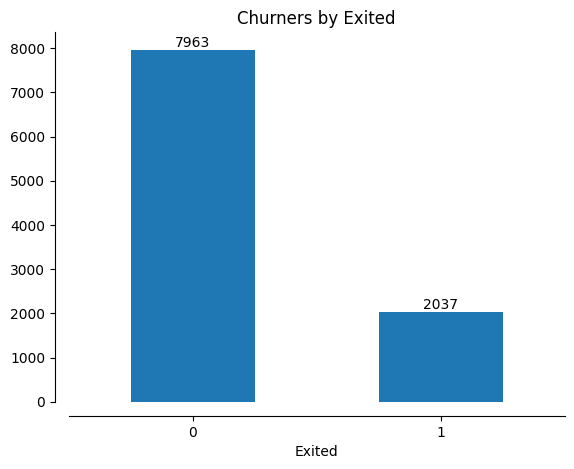

In [83]:
import seaborn as sns
import matplotlib.pyplot as plt
ax = churn_cus_info["Exited"].value_counts().plot.bar()
ax.bar_label(ax.containers[0], fmt=lambda x: f"{x:.0f}")
plt.title("Churners by Exited")
plt.xlabel("Exited")
sns.despine(offset=10)
plt.show()



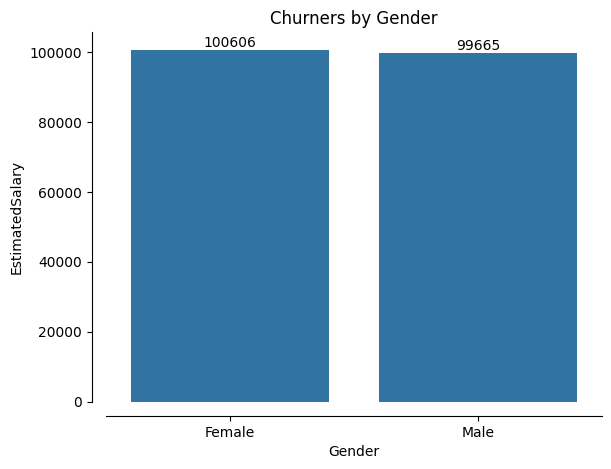

In [84]:
ax_1 = sns.barplot(data=churn_cus_info, x="Gender", y = "EstimatedSalary", errorbar= None)
ax_1.bar_label(ax_1.containers[0], fmt=lambda x: f"{x:.0f}")
plt.title("Churners by Gender")
sns.despine(offset=10)

<function matplotlib.pyplot.show(close=None, block=None)>

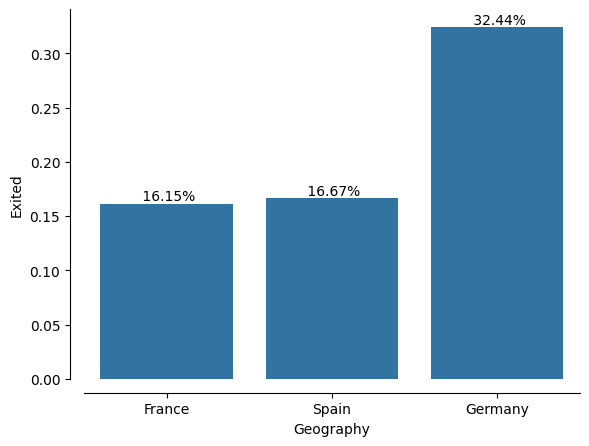

In [85]:
ax_2 = sns.barplot(data= churn_cus_info, x = "Geography", y = "Exited", errorbar= None)
ax_2.bar_label(ax_2.containers[0], fmt = lambda x: f"{x: .2%}")

sns.despine(offset=10)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

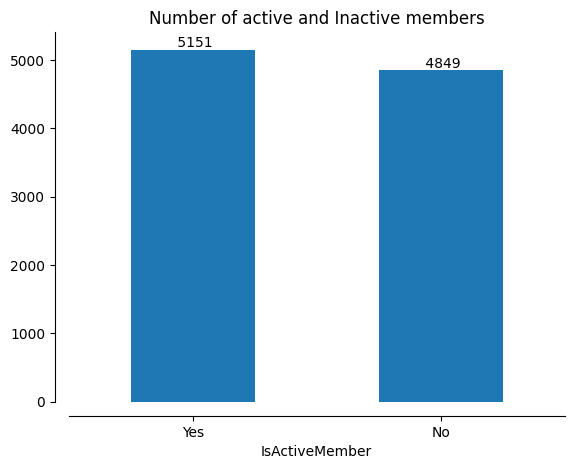

In [86]:
ax_3 = churn_cus_info["IsActiveMember"].value_counts().plot.bar()
ax_3.bar_label(ax_3.containers[0], fmt = lambda x : f"{x: .0f}")
plt.title("Number of active and Inactive members")
sns.despine(offset=10)
plt.show

# 1. (Loop) Build a bar chart displaying the count of churners (Exited=1) vs. non-churners (Exited=0)

C:\Users\Ahasan Hasan\AppData\Local\Temp\ipykernel_18508\1447808511.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in churn_cus_info.drop("Surname",axis=1).select_dtypes("object"):


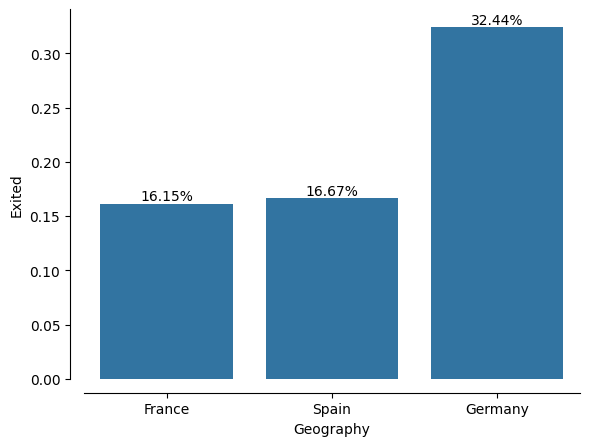

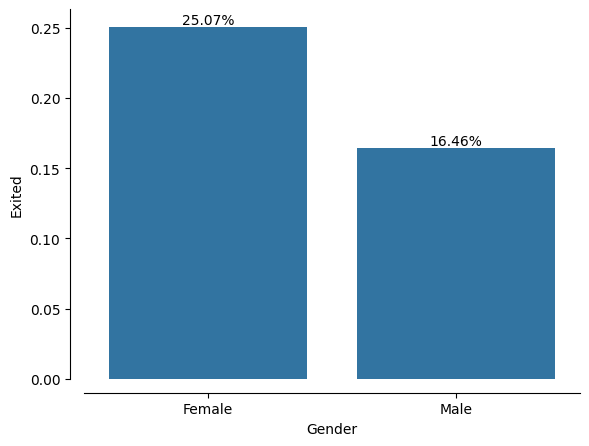

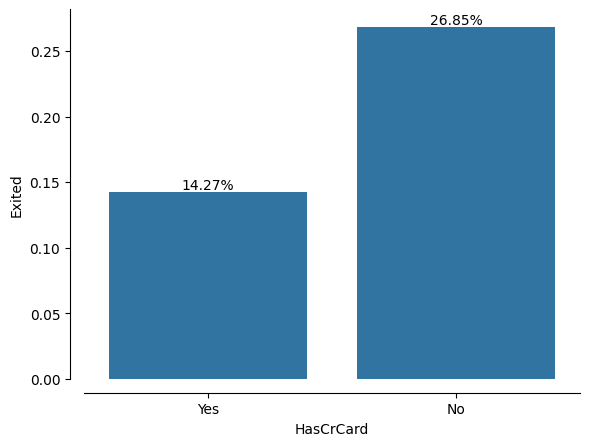

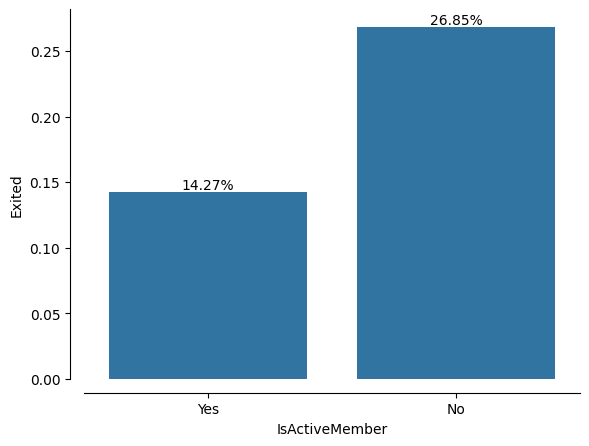

In [87]:
for col in churn_cus_info.drop("Surname",axis=1).select_dtypes("object"):
    ax_4 = sns.barplot(data=churn_cus_info, x=col, y="Exited", errorbar=None)
    ax_4.bar_label(ax_4.containers[0],fmt=lambda x: f"{x:.2%}")
    sns.despine(offset=10)
    plt.show()

# 3. Build box plots for each numeric field, broken out by churners vs. non-churners

In [88]:
churn_cus_info.select_dtypes("float").info()

<class 'pandas.DataFrame'>
Index: 10000 entries, 0 to 10000
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Age              10000 non-null  float64
 1   EstimatedSalary  10000 non-null  float64
 2   Balance          10000 non-null  float64
dtypes: float64(3)
memory usage: 312.5 KB


In [89]:
churn_cus_info.select_dtypes(["float","int"])

,CustomerId,CreditScore,Age,EstimatedSalary,Balance,NumOfProducts,Tenure,Exited
0,15634602,619,42.0,101348.88,0.00,1,2,1
2,15647311,608,41.0,112542.58,83807.86,1,1,0
3,15619304,502,42.0,113931.57,159660.80,3,8,1
4,15701354,699,39.0,93826.63,0.00,2,1,0
5,15737888,850,43.0,79084.10,125510.82,1,2,0
...,...,...,...,...,...,...,...,...
9996,15606229,771,39.0,96270.64,0.00,2,5,0
9997,15569892,516,35.0,101699.77,57369.61,1,10,0
9998,15584532,709,36.0,42085.58,0.00,1,7,1
9999,15682355,772,42.0,92888.52,75075.31,2,3,1


#  3. (Manual) Build box plots for each numeric field, broken out by churners vs. non-churners

Text(0.5, 1.0, 'Number of customers exited by Age')

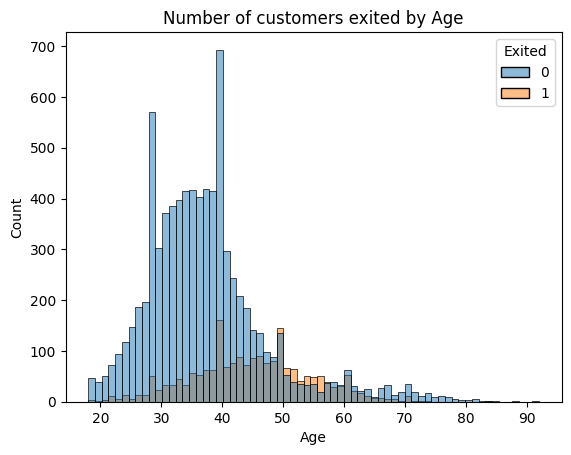

In [90]:
sns.histplot(data=churn_cus_info, x="Age", hue="Exited")
plt.title("Number of customers exited by Age")


<Axes: ylabel='Age'>

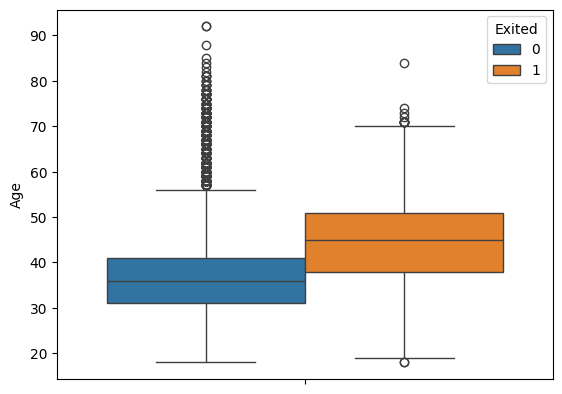

In [91]:
sns.boxplot(data=churn_cus_info, y="Age", hue="Exited")

# 3.(Loop) Build box plots for each numeric field, broken out by churners vs. non-churners

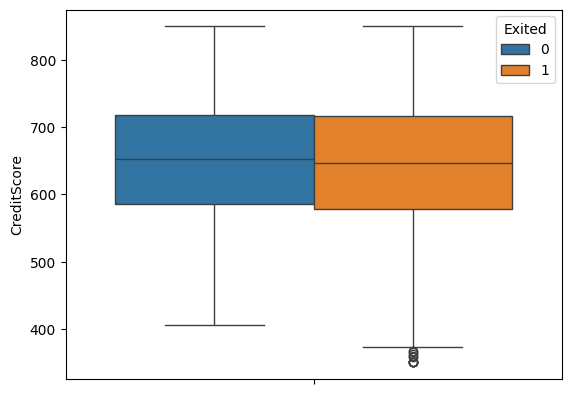

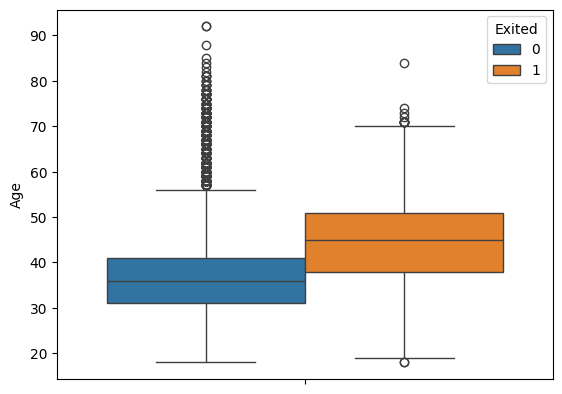

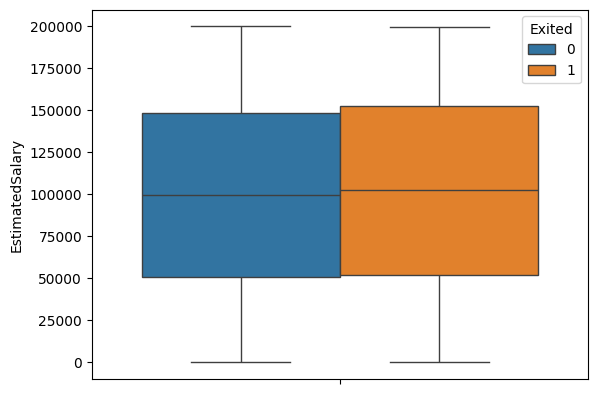

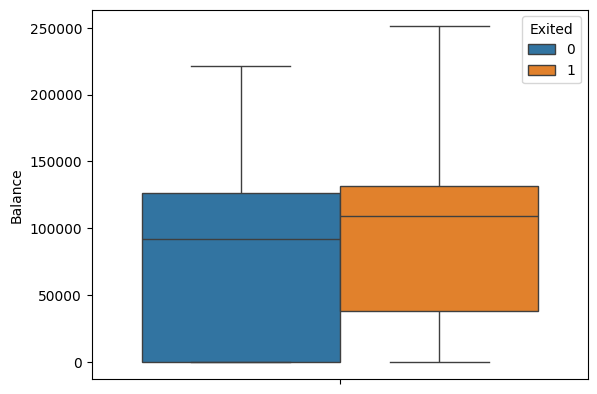

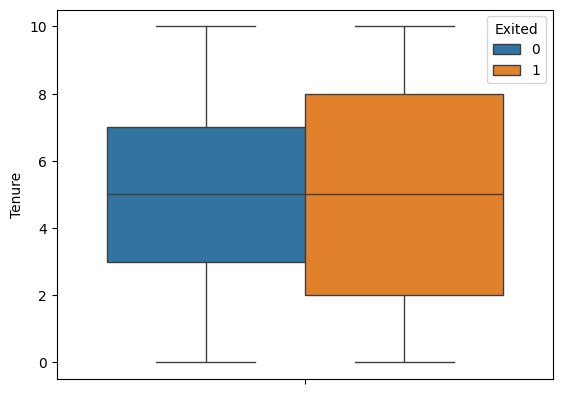

In [92]:
for col in churn_cus_info.drop(["CustomerId","NumOfProducts","Exited"],axis=1).select_dtypes("number"):
    sns.boxplot(data=churn_cus_info, y=col, hue="Exited")

    plt.show()


# 4. (Loop) Build histograms for each numeric field, broken out by churners vs. non-churners


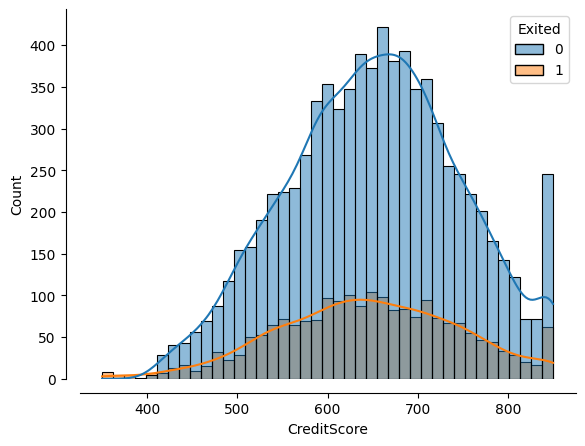

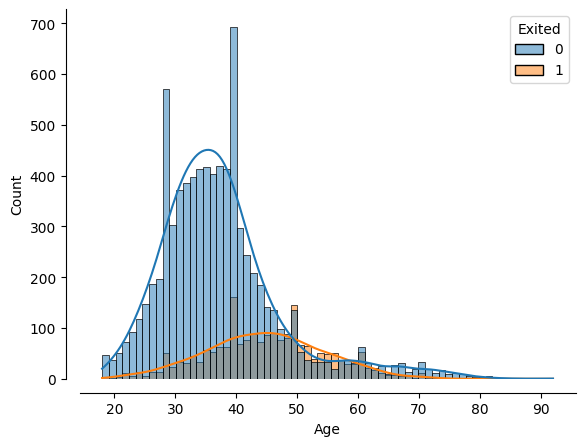

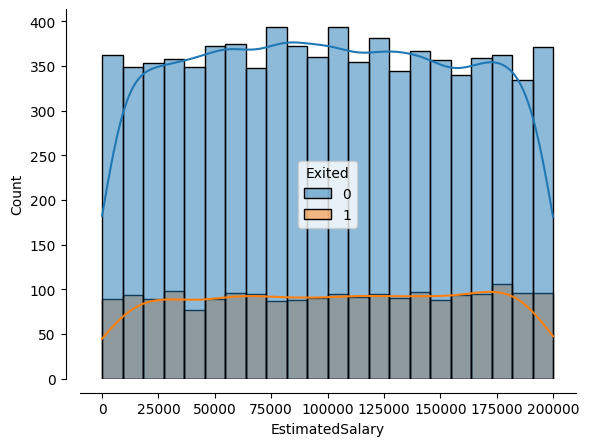

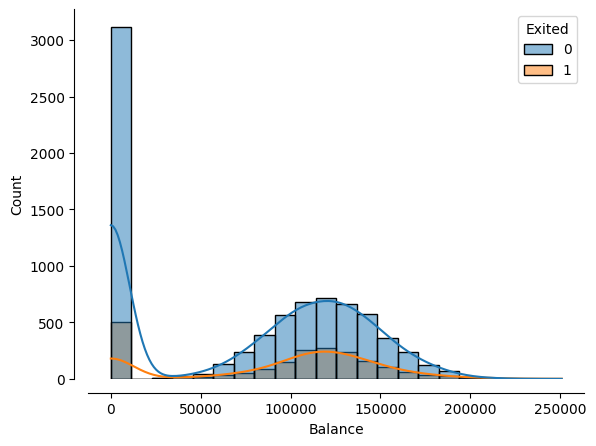

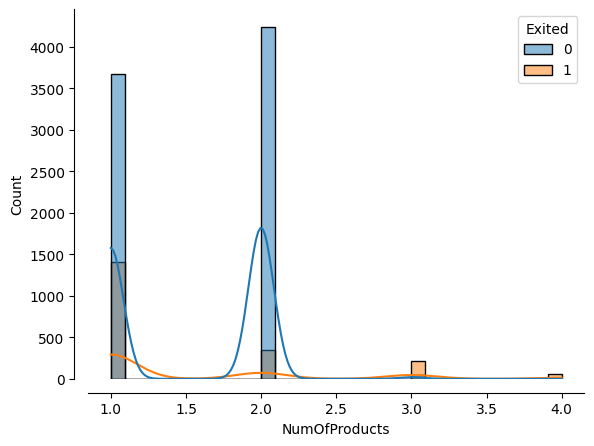

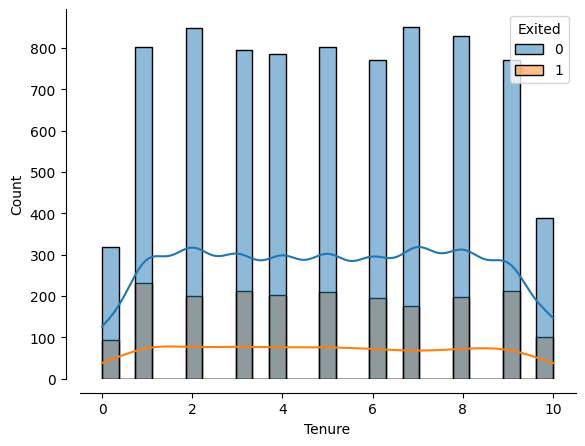

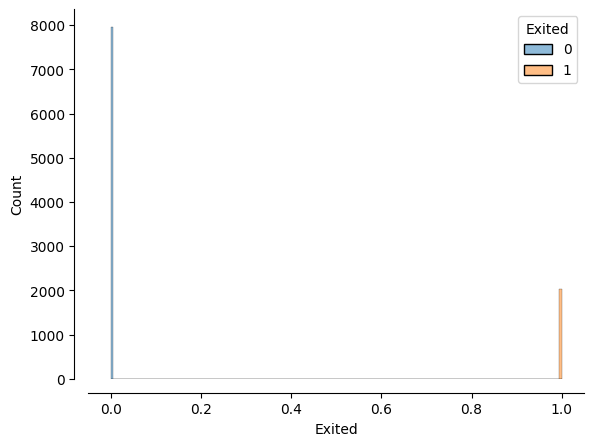

In [93]:
for col in churn_cus_info.drop("CustomerId",axis= 1).select_dtypes("number"):
    sns.histplot(churn_cus_info, x=col, hue="Exited",kde=True)
    sns.despine(offset=10)
    plt.show()

Objective 4
Prepare the data for modeling & Feature Engineering

Your final objective is to prepare the data for modeling through feature selection, feature engineering, and data splitting.

Create a new dataset that excludes any columns that aren’t be suitable for modeling


Create dummy variables for categorical fields


Create a new “balance_v_income” feature, which divides a customer’s bank balance by their estimated salary, then visualize that feature vs. churn status

In [94]:
churn_cus_info.head()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure,IsActiveMember,Exited
0,15634602,Hargrave,619,France,Female,42.0,101348.88,0.00,1,Yes,2,Yes,1
2,15647311,Hill,608,Spain,Female,41.0,112542.58,83807.86,1,Yes,1,Yes,0
3,15619304,Onio,502,France,Female,42.0,113931.57,159660.80,3,No,8,No,1
4,15701354,Boni,699,France,Female,39.0,93826.63,0.00,2,No,1,No,0
5,15737888,Mitchell,850,Spain,Female,43.0,79084.10,125510.82,1,Yes,2,Yes,0


In [95]:
modelling_df = churn_cus_info.drop(["CustomerId","Surname"],axis=1)
modelling_df

,CreditScore,Geography,Gender,Age,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure,IsActiveMember,Exited
0,619,France,Female,42.0,101348.88,0.00,1,Yes,2,Yes,1
2,608,Spain,Female,41.0,112542.58,83807.86,1,Yes,1,Yes,0
3,502,France,Female,42.0,113931.57,159660.80,3,No,8,No,1
4,699,France,Female,39.0,93826.63,0.00,2,No,1,No,0
5,850,Spain,Female,43.0,79084.10,125510.82,1,Yes,2,Yes,0
...,...,...,...,...,...,...,...,...,...,...,...
9996,771,France,Male,39.0,96270.64,0.00,2,No,5,No,0
9997,516,France,Male,35.0,101699.77,57369.61,1,Yes,10,Yes,0
9998,709,France,Female,36.0,42085.58,0.00,1,Yes,7,Yes,1
9999,772,Germany,Male,42.0,92888.52,75075.31,2,No,3,No,1


# Create dummy variables for categorical fields

In [96]:
pd.get_dummies(modelling_df,drop_first=True)


,CreditScore,Age,EstimatedSalary,Balance,NumOfProducts,Tenure,Exited,Geography_Germany,Geography_Spain,Gender_Male,HasCrCard_Yes,IsActiveMember_Yes
0,619,42.0,101348.88,0.00,1,2,1,False,False,False,True,True
2,608,41.0,112542.58,83807.86,1,1,0,False,True,False,True,True
3,502,42.0,113931.57,159660.80,3,8,1,False,False,False,False,False
4,699,39.0,93826.63,0.00,2,1,0,False,False,False,False,False
5,850,43.0,79084.10,125510.82,1,2,0,False,True,False,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...
9996,771,39.0,96270.64,0.00,2,5,0,False,False,True,False,False
9997,516,35.0,101699.77,57369.61,1,10,0,False,False,True,True,True
9998,709,36.0,42085.58,0.00,1,7,1,False,False,False,True,True
9999,772,42.0,92888.52,75075.31,2,3,1,True,False,True,False,False


# Create a new “balance_v_income” feature, which divides a customer’s bank balance by their estimated salary, then visualize that feature vs. churn status


In [97]:
modelling_df["Balance_vs_salary"] = modelling_df["Balance"]/ modelling_df["EstimatedSalary"]
modelling_df.head()

,CreditScore,Geography,Gender,Age,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure,IsActiveMember,Exited,Balance_vs_salary
0,619,France,Female,42.0,101348.88,0.00,1,Yes,2,Yes,1,0.000000
2,608,Spain,Female,41.0,112542.58,83807.86,1,Yes,1,Yes,0,0.744677
3,502,France,Female,42.0,113931.57,159660.80,3,No,8,No,1,1.401375
4,699,France,Female,39.0,93826.63,0.00,2,No,1,No,0,0.000000
5,850,Spain,Female,43.0,79084.10,125510.82,1,Yes,2,Yes,0,1.587055


<Axes: ylabel='Balance_vs_salary'>

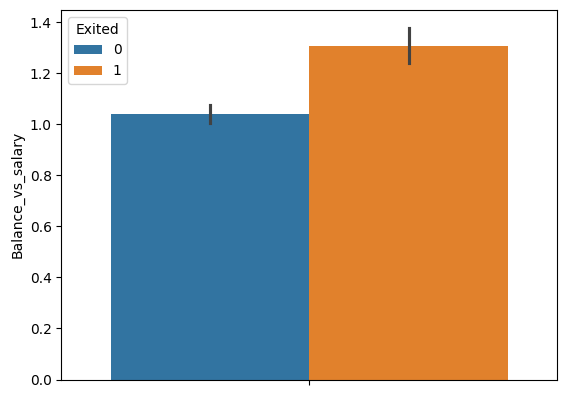

In [98]:
sns.barplot(data=modelling_df.query("Balance_vs_salary < 10"), y="Balance_vs_salary", hue="Exited")

<Axes: ylabel='Balance_vs_salary'>

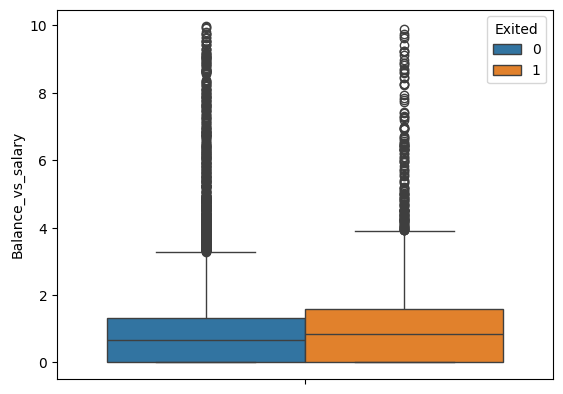

In [99]:
sns.boxplot(data=modelling_df.query("Balance_vs_salary < 10"), y="Balance_vs_salary", hue="Exited")

Classification project >>>>